# Détecteur de Spam AT&T

### Problématique

L'un des principaux problèmes rencontrés par les utilisateurs d'AT&T est l'exposition constante aux messages indésirables (spams). AT&T a pu pendant un certain temps signaler manuellement ces messages, mais l'entreprise recherche désormais un moyen automatisé de détecter les spams afin de protéger ses utilisateurs.

### Objectif

Construire un détecteur de spam capable de signaler automatiquement les messages indésirables dès leur réception, en se basant uniquement sur le contenu du SMS.

### Approche

- Construire un Modèle Baseline
- Utiliser le Transfert Learning + Fine Tuning
- Suivre l'évolution de la performance

## 1. Importation des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

import torch
import torch.nn as nn
from torchinfo import summary
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
from tokenizers import Tokenizer, models, pre_tokenizers, trainers
from transformers import PreTrainedTokenizerFast
from sklearn.metrics import classification_report, confusion_matrix
from transformers import (
    DistilBertForSequenceClassification, DistilBertTokenizer, Trainer, 
    TrainingArguments, AutoModelForSequenceClassification, AutoTokenizer, EarlyStoppingCallback
)

## 2. Chargement et exploration des données

In [2]:
# Chargement du fichier CSV fourni avec le projet.
# Le fichier contient 5 colonnes : 'v1' (label), 'v2' (message) et 3 colonnes parasites quasi-vides.
# L'encodage latin-1 est requis car le fichier contient des caractères non-UTF-8.

df = pd.read_csv('./data/spam.csv', encoding='latin-1')

print(f"Dimensions brutes : {df.shape}")
print(f"Colonnes détectées : {df.columns.tolist()}")
df.head(10)

Dimensions brutes : (5572, 5)
Colonnes détectées : ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


In [3]:
# Nettoyage du DataFrame : conservation des deux colonnes utiles et renommage.
# Les colonnes 'Unnamed: 2/3/4' sont quasi-vides (moins de 1 % de valeurs renseignées)
# et ne contiennent pas d'information exploitable pour la classification.

df = df[['v1', 'v2']].copy()
df.columns = ['label', 'message']

# Suppression des éventuels doublons pour éviter de biaiser l'évaluation
nb_doublons = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

print(f"Doublons supprimés  : {nb_doublons}")
print(f"Dimensions finales  : {df.shape}")
print(f"Valeurs manquantes  : {df.isnull().sum().sum()}")
df.head()

Doublons supprimés  : 403
Dimensions finales  : (5169, 2)
Valeurs manquantes  : 0


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
# Distribution des classes spam / ham.
# Le jeu de données est déséquilibré : environ 87 % de ham et 13 % de spam.

print("Distribution des classes :")
print(df['label'].value_counts())
print()
print(f"Proportion de spam : {df['label'].value_counts(normalize=True)['spam']:.2%}")
print(f"Proportion de ham  : {df['label'].value_counts(normalize=True)['ham']:.2%}")

Distribution des classes :
label
ham     4516
spam     653
Name: count, dtype: int64

Proportion de spam : 12.63%
Proportion de ham  : 87.37%


In [6]:
# Encodage de la variable cible : 'spam' -> 1, 'ham' -> 0.
# LabelEncoder assigne les valeurs par ordre alphabétique : ham = 0, spam = 1.

le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])

print('Correspondance des labels :')
for cls, enc in zip(le.classes_, le.transform(le.classes_)):
    print(f"  '{cls}' -> {enc}")

Correspondance des labels :
  '0' -> 0
  '1' -> 1


## 3. Modèle Baseline: Tokenizer + Embeddings + MLP

In [7]:
# Split avant de construire le vocabulaire
X_train, X_test, y_train, y_test = train_test_split(
    df["message"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [8]:
# Tokenizer WordLevel : vocabulaire appris sur le train uniquement
tokenizer_backend = Tokenizer(
    models.WordLevel(unk_token="[UNK]")
)
tokenizer_backend.pre_tokenizer = pre_tokenizers.Whitespace()

trainer = trainers.WordLevelTrainer(
    special_tokens=["[PAD]", "[UNK]"],
    min_frequency=1
)

tokenizer_backend.train_from_iterator(X_train, trainer=trainer)

tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=tokenizer_backend,
    unk_token="[UNK]",
    pad_token="[PAD]"
)

vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id

print("Vocab size:", vocab_size)
print("PAD ID:", pad_id)
print(tokenizer.tokenize(X_train[0]))

Vocab size: 9683
PAD ID: 0
['Cool', '.', 'So', 'how', 'come', 'you', 'havent', 'been', 'wined', 'and', 'dined', 'before', '?']


In [9]:
# On fixe la longuer maximale des message à 128
MAX_LEN = 128

def encode_messages(messages):
    encoded = tokenizer(
        messages,
        truncation=True,
        max_length=MAX_LEN,
        padding="max_length",
        return_tensors="pt"
    )
    return encoded["input_ids"]

# Tokenization des messages train et test avec le vocabulaire appris que sur train
X_train = encode_messages(X_train)
X_test = encode_messages(X_test)

y_train = torch.tensor(y_train, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [11]:
class SpamDataset(Dataset):
    def __init__(self, input_ids, labels):
        self.input_ids = input_ids
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.labels[idx]


train_dataset = SpamDataset(X_train, y_train)
test_dataset = SpamDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False
)

In [12]:
class SpamClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128,
                 hidden1=64, hidden2=32, pad_id=0):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_id
        )

        self.fc1 = nn.Linear(embedding_dim, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.output = nn.Linear(hidden2, 1)

        self.relu = nn.ReLU()

    def forward(self, input_ids):
        # [batch, seq_len, embedding_dim]
        embeddings = self.embedding(input_ids)

        # Masquer le padding dans le calcul de la moyenne
        mask = (input_ids != self.embedding.padding_idx).unsqueeze(-1)
        masked_embeddings = embeddings * mask

        summed = masked_embeddings.sum(dim=1)
        lengths = mask.sum(dim=1).clamp(min=1)
        pooled = summed / lengths

        x = self.relu(self.fc1(pooled))
        x = self.relu(self.fc2(x))
        logits = self.output(x).squeeze(-1)

        return logits


In [19]:
model_baseline = SpamClassifier(
    vocab_size=vocab_size,
    embedding_dim=128,
    hidden1=64,
    hidden2=32,
    pad_id=pad_id
)
print(model_baseline)
summary(model_baseline)

SpamClassifier(
  (embedding): Embedding(9683, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)


Layer (type:depth-idx)                   Param #
SpamClassifier                           --
├─Embedding: 1-1                         1,239,424
├─Linear: 1-2                            8,256
├─Linear: 1-3                            2,080
├─Linear: 1-4                            33
├─ReLU: 1-5                              --
Total params: 1,249,793
Trainable params: 1,249,793
Non-trainable params: 0

In [20]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model_baseline = model_baseline.to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_baseline.parameters(), lr=1e-3)

EPOCHS = 3

# Training loop
hist_loss_train = []
hist_loss_val = []
for epoch in range(EPOCHS):
    model_baseline.train()
    total_loss_train = 0.0

    for input_ids, labels in train_loader:
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model_baseline(input_ids)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss_train += loss.item()

    avg_loss_train = total_loss_train / len(train_loader)
    hist_loss_train.append(avg_loss_train)

    model_baseline.eval()
    total_loss_val = 0.0
    with torch.no_grad():
        for input_ids, labels in test_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model_baseline(input_ids)
            loss = criterion(logits, labels)

            total_loss_val += loss.item()

        avg_loss_val = total_loss_val / len(test_loader)
        hist_loss_val.append(avg_loss_val)

    print(f"Epoch {epoch + 1}/{EPOCHS} - train_loss: {avg_loss_train:.4f} - val_loss: {avg_loss_val:.4f}")

Epoch 1/3 - train_loss: 0.2750 - val_loss: 0.1536
Epoch 2/3 - train_loss: 0.1143 - val_loss: 0.1030
Epoch 3/3 - train_loss: 0.0502 - val_loss: 0.0846


Rapport de classification - Test Set - Modèle Baseline
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.91      0.90      0.91       131

    accuracy                           0.98      1034
   macro avg       0.95      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



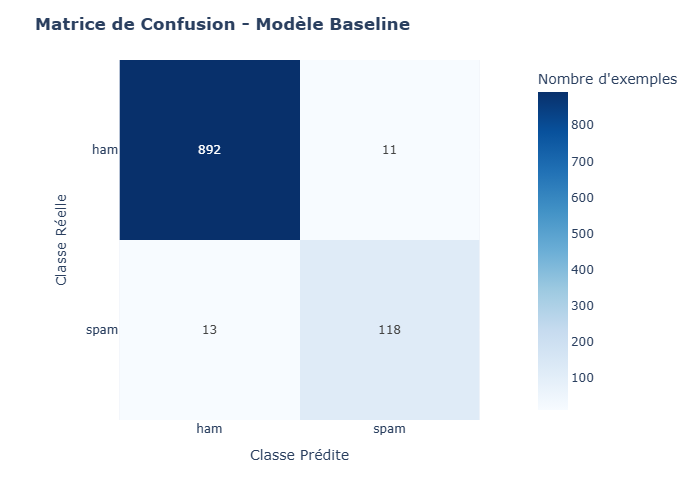

In [21]:
# Evaluation du modèle
model_baseline.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for input_ids, labels in test_loader:
        input_ids = input_ids.to(device)

        logits = model_baseline(input_ids)
        probs = torch.sigmoid(logits)

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

predictions = (np.array(all_probs) >= 0.5).astype(int)

print("Rapport de classification - Test Set - Modèle Baseline")
print(classification_report(all_labels, predictions,
                            target_names=["ham", "spam"]))

cm_base = confusion_matrix(all_labels, predictions)
fig = px.imshow(
    cm_base,
    text_auto=True, 
    labels=dict(x="Prédiction", y="Réel", color="Nombre d'exemples"),
    x=["ham", "spam"],
    y=["ham", "spam"],
    color_continuous_scale="Blues"
)
fig.update_layout(
    title="<b>Matrice de Confusion - Modèle Baseline</b>",
    xaxis_title="Classe Prédite",
    yaxis_title="Classe Réelle",
)
# Graphique Matrice de Confusion
fig.show(renderer='png')

La performance du modèle simple de baseline est très correcte avec un score de recall à 90%, et un F1 score de 91%. Le modèle peut basculer dans l'overfitting assez rapidement, if faut garder une petite valeurs de nombre de EPOCHS.

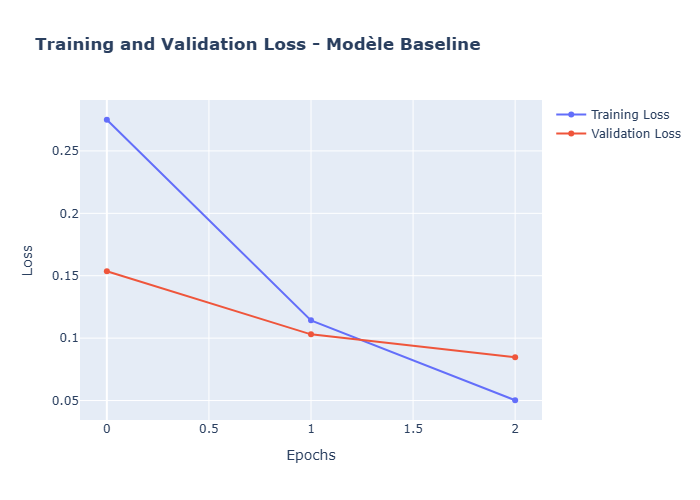

In [22]:
# Graphe Training loss et Validation loss
fig = go.Figure(
    [
        go.Scatter(y=hist_loss_train, name="Training Loss"),
        go.Scatter(y=hist_loss_val, name="Validation Loss"),
    ]
)

fig.update_layout(
    title="<b>Training and Validation Loss - Modèle Baseline</b>",
    xaxis_title="Epochs",
    yaxis_title="Loss",
)
fig.show(renderer='png')

## 4. Transfert learning avec DistilBERT

In [23]:
model_name = "distilbert-base-uncased"
tokenizer = DistilBertTokenizer.from_pretrained(model_name)
model = DistilBertForSequenceClassification.from_pretrained(model_name, num_labels=2)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [24]:
print(model)
summary(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


Layer (type:depth-idx)                                  Param #
DistilBertForSequenceClassification                     --
├─DistilBertModel: 1-1                                  --
│    └─Embeddings: 2-1                                  --
│    │    └─Embedding: 3-1                              23,440,896
│    │    └─Embedding: 3-2                              393,216
│    │    └─LayerNorm: 3-3                              1,536
│    │    └─Dropout: 3-4                                --
│    └─Transformer: 2-2                                 --
│    │    └─ModuleList: 3-5                             42,527,232
├─Linear: 1-2                                           590,592
├─Linear: 1-3                                           1,538
├─Dropout: 1-4                                          --
Total params: 66,955,010
Trainable params: 66,955,010
Non-trainable params: 0

In [25]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    df["message"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [26]:
class DistilSpamDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        # Tokenisation directe de toute la liste d'un coup
        self.encodings = tokenizer(
            texts, 
            padding=True, 
            truncation=True, 
            max_length=max_length, 
            return_tensors="pt"
        )
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Récupère les inputs tokenisés pour un index donné et ajoute le label
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

In [27]:
train_dataset = DistilSpamDataset(X_train, y_train, tokenizer)
test_dataset = DistilSpamDataset(X_test, y_test, tokenizer)

# Configurer les arguments d'entraînement
training_args = TrainingArguments(
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=10,  # l'early stopping arrêtera avant si besoin
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

# Initialiser le Trainer
trainer_distil = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# Lancer l'entraînement
trainer_distil.train()

Epoch,Training Loss,Validation Loss
1,No log,0.039656
2,0.065398,0.038928
3,0.065398,0.042277
4,0.013421,0.036754
5,0.013421,0.037913
6,0.001335,0.044277


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1554, training_loss=0.02579471558761547, metrics={'train_runtime': 380.2873, 'train_samples_per_second': 108.734, 'train_steps_per_second': 6.811, 'total_flos': 821629040163840.0, 'train_loss': 0.02579471558761547, 'epoch': 6.0})


--- Rapport de classification - DistilBERT ---
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       903
        spam       0.98      0.95      0.97       131

    accuracy                           0.99      1034
   macro avg       0.99      0.98      0.98      1034
weighted avg       0.99      0.99      0.99      1034

--- Matrice de confusion finale -  - DistilBERT---


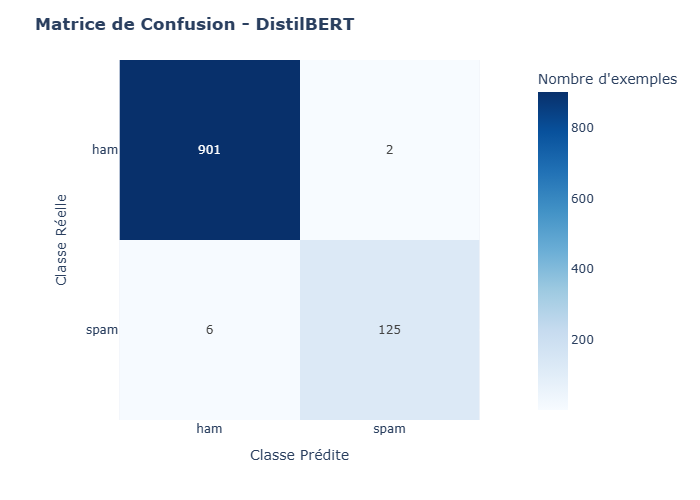

In [28]:
# Evaluation du modèle
predictions_output = trainer_distil.predict(test_dataset)

# Extraire les logits bruts et appliquer un argmax pour obtenir les classes (0 ou 1)
logits = predictions_output.predictions
preds = np.argmax(logits, axis=-1)

# Récupérer les vrais labels du dataset de test
true_labels = predictions_output.label_ids

# 4. Afficher les métriques finales
print("\n--- Rapport de classification - DistilBERT ---")
print(classification_report(
    true_labels,
    preds,
    target_names=["ham", "spam"],
    zero_division=0
))

print("--- Matrice de confusion finale -  - DistilBERT---")
cm_distil = confusion_matrix(true_labels, preds)
fig = px.imshow(
    cm_distil,
    text_auto=True, 
    labels=dict(x="Prédiction", y="Réel", color="Nombre d'exemples"),
    x=["ham", "spam"],
    y=["ham", "spam"],
    color_continuous_scale="Blues"
)
fig.update_layout(
    title="<b>Matrice de Confusion - DistilBERT</b>",
    xaxis_title="Classe Prédite",
    yaxis_title="Classe Réelle",
)
# Graphique Matrice de Confusion
fig.show(renderer='png')

## 5. Transfert learning avec RoBERTa

In [30]:
model_name = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [31]:
print(model)
summary(model)

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
             

Layer (type:depth-idx)                                       Param #
RobertaForSequenceClassification                             --
├─RobertaModel: 1-1                                          --
│    └─RobertaEmbeddings: 2-1                                --
│    │    └─Embedding: 3-1                                   38,603,520
│    │    └─Embedding: 3-2                                   768
│    │    └─LayerNorm: 3-3                                   1,536
│    │    └─Dropout: 3-4                                     --
│    │    └─Embedding: 3-5                                   394,752
│    └─RobertaEncoder: 2-2                                   --
│    │    └─ModuleList: 3-6                                  85,054,464
├─RobertaClassificationHead: 1-2                             --
│    └─Linear: 2-3                                           590,592
│    └─Dropout: 2-4                                          --
│    └─Linear: 2-5                                           1,538
To

In [32]:
# Split
X_train, X_test, y_train, y_test = train_test_split(
    df["message"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

In [33]:
class RobSpamDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        # Tokenisation directe de toute la liste d'un coup
        self.encodings = tokenizer(
            texts, 
            padding=True, 
            truncation=True, 
            max_length=max_length, 
            return_tensors="pt"
        )
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Récupère les inputs tokenisés pour un index donné et ajoute le label
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

In [34]:
train_dataset = RobSpamDataset(X_train, y_train, tokenizer)
test_dataset = RobSpamDataset(X_test, y_test, tokenizer)

# Configurer les arguments d'entraînement
training_args = TrainingArguments(
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=10,  # l'early stopping arrêtera avant si besoin
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

# Initialiser le Trainer
trainer_rob = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# Lancer l'entraînement
trainer_rob.train()

Epoch,Training Loss,Validation Loss
1,No log,0.031213
2,0.062613,0.051830
3,0.062613,0.036195


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=777, training_loss=0.046515572178471194, metrics={'train_runtime': 372.7781, 'train_samples_per_second': 110.924, 'train_steps_per_second': 6.948, 'total_flos': 815973160435200.0, 'train_loss': 0.046515572178471194, 'epoch': 3.0})


--- Rapport de classification - RoBERTa ---
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00       903
        spam       0.97      0.98      0.97       131

    accuracy                           0.99      1034
   macro avg       0.98      0.99      0.98      1034
weighted avg       0.99      0.99      0.99      1034

--- Matrice de confusion finale -  - RoBERTa---


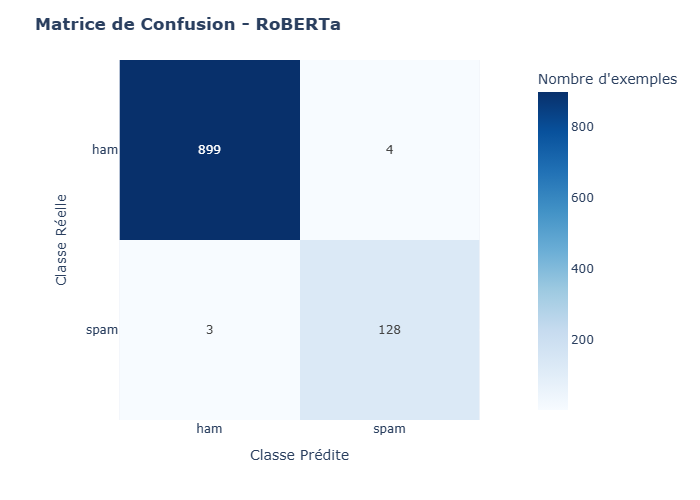

In [37]:
# Evaluation du modèle
predictions_output = trainer_rob.predict(test_dataset)

# Extraire les logits bruts et appliquer un argmax pour obtenir les classes (0 ou 1)
logits = predictions_output.predictions
preds = np.argmax(logits, axis=-1)

# Récupérer les vrais labels du dataset de test
true_labels = predictions_output.label_ids

# 4. Afficher les métriques finales
print("\n--- Rapport de classification - RoBERTa ---")
print(classification_report(
    true_labels,
    preds,
    target_names=["ham", "spam"],
    zero_division=0
))

print("--- Matrice de confusion finale -  - RoBERTa---")
cm_rob = confusion_matrix(true_labels, preds)
fig = px.imshow(
    cm_rob,
    text_auto=True, 
    labels=dict(x="Prédiction", y="Réel", color="Nombre d'exemples"),
    x=["ham", "spam"],
    y=["ham", "spam"],
    color_continuous_scale="Blues"
)
fig.update_layout(
    title="<b>Matrice de Confusion - RoBERTa</b>",
    xaxis_title="Classe Prédite",
    yaxis_title="Classe Réelle",
)
# Graphique Matrice de Confusion
fig.show(renderer='png')

## 6. Comparaison des performances & Conclusion

In [36]:
# Tableau récapitulatif des performances des modèles.

resultats = pd.DataFrame({
    'Modèle': ['Baseline', 'DistilBERT', 'RoBERTa'],
    'Recall' : [cm_base[1,1] / (cm_base[1,0] + cm_base[1,1]),
                cm_distil[1,1] / (cm_distil[1,0] + cm_distil[1,1]),
                cm_rob[1,1] / (cm_rob[1,0] + cm_rob[1,1])],
    'Precision' : [cm_base[1,1] / (cm_base[0,1] + cm_base[1,1]),
                cm_distil[1,1] / (cm_distil[0,1] + cm_distil[1,1]),
                cm_rob[1,1] / (cm_rob[0,1] + cm_rob[1,1])],
}).set_index('Modèle')

# Calculer les scores F1
resultats['F1_score'] = 2 * resultats['Recall'] * resultats['Precision'] / (resultats['Recall'] + resultats['Precision'])
resultats = resultats.round(2)

print('=' * 68)
print('Tableau comparatif des performances sur le jeu de test')
print('=' * 68)
print(resultats.to_string())

Tableau comparatif des performances sur le jeu de test
            Recall  Precision  F1_score
Modèle                                 
Baseline      0.90       0.91      0.91
DistilBERT    0.95       0.98      0.97
RoBERTa       0.98       0.97      0.97


Les modèles de type BERT préentrainés sont plus performants que notre modèle basique. C'est tout à fait attendu, puisqu'ils sont entrainés sur des milliards de mots.

On note qu'il y a une légère amélioration au score recall dans et RoBERTa par rapport au DistilBERT. Ils laissent passer moins de messages spam. Néanmoins, le modèle DistilBERT est beaucoup plus léger et moins gourmand en terme de ressources.

--- 

Nous avons construit et comparé des modèles de deep learning pour détecter automatiquement les SMS indésirables sur le jeu de données spam.csv (5 572 messages, 13 % de spam).

**Embedding + MLP** : architecture légère entraînée entièrement sur nos données.

**Transfert Learning + Fine Tuning avec DistilBERT/RoBERTa**: modèles pré-entraînés sur des milliards de mots, auxquels une tête de classification a été ajoutée, et qui sont affinés (Fine tuning) sur notre corpus. Ils apportent une compréhension profonde du contexte linguistique `sans nécessiter de grandes quantités de données d'entraînement.`

#### Recommandation
Le choix entre les modèles dépend des contraintes opérationnelles d'AT&T :
- Priorité à la **vitesse d'inférence** et à la **légèreté** : "Embedding + MLP" ou DistilBERT.
- Priorité à la **performance**: RoBERTa ou DistilBERT.